In [1]:
import sys
sys.path.append("src")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
sys.path.append("First_pp")
from peak_significance import *
from E_resolution import load_calibration

In [3]:
coeffs = load_calibration("data/calibration.json")
ch_t, n_t, L_t = load_run("First_pp/positron_maybe.csv")
ch_b, n_b, L_b = load_run("First_pp/co60_background.csv")
print("live times (s):", L_t, L_b)

live times (s): 1649.0 273.0


In [4]:
check_lines(ch_t, n_t, coeffs)
check_lines(ch_b, n_b, coeffs)

 1173.23 keV: predicted ch   5303.4, strongest bin     5305, offset +1.6 ch
 1332.49 keV: predicted ch   6044.1, strongest bin     6045, offset +0.9 ch
 1173.23 keV: predicted ch   5303.4, strongest bin     5306, offset +2.6 ch
 1332.49 keV: predicted ch   6044.1, strongest bin     6046, offset +1.9 ch


In [5]:
m, c, table, ch_of = run_calibration(ch_t, n_t, coeffs, energies=(1173.23, 1332.49), verbose=True)
mu_t = ch_of(511.0)                      # 511 keV channel for THIS run

m, c, table, ch_of = run_calibration(ch_b, n_b, coeffs, energies=(1173.23, 1332.49), verbose=True)
mu_b = ch_of(511.0)       # and for the blank

print(mu_t, mu_b)

  E_keV  centroid  centroid_err  fwhm_ch  resid_ch
1173.23   5303.65          0.03    12.88      -0.0
1332.49   6043.85          0.03    13.11      -0.0
  channel = 4.6478 * E + -149.25   (channel of 0 keV: -149.3)
  E_keV  centroid  centroid_err  fwhm_ch  resid_ch
1173.23   5305.73          0.05    11.34      -0.0
1332.49   6045.88          0.05    11.99      -0.0
  channel = 4.6475 * E + -146.84   (channel of 0 keV: -146.8)
2225.7555113392677 2228.024129188139


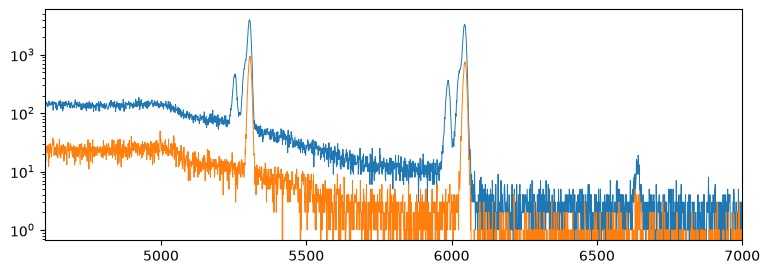

In [6]:
plt.figure(figsize=(9,3))
plt.semilogy(ch_t, n_t, lw=0.7); plt.xlim(4600, 7000)
plt.semilogy(ch_b, n_b, lw=0.7); plt.xlim(4600, 7000)
plt.show()

In [14]:
mu = channel_of(511.0, coeffs)
# width from your resolution fit
fwhm_keV = np.sqrt(21.746 + -0.0097 * 511.0)   # used data from resolution results .
slope = coeffs[1]                       # keV per channel (linear calibration)
sigma = fwhm_keV / slope / 2.355        # in channels
print(mu, sigma)

2223.39016418159 8.091194988770997


In [15]:
ft = peak_fit(ch_t, n_t, mu, sigma)
fb = peak_fit(ch_b, n_b, mu, sigma)
print(f"with tin: area {ft['area']:.0f} +/- {ft['area_err']:.0f}, Z = {ft['Z']:.1f} sigma")
print(f"blank   : area {fb['area']:.0f} +/- {fb['area_err']:.0f}, Z = {fb['Z']:.1f} sigma")

rate_t, rate_b = ft['area']/L_t, fb['area']/L_b
err = np.hypot(ft['area_err']/L_t, fb['area_err']/L_b)
print(f"excess 511 rate (tin - blank): {rate_t-rate_b:.4f} +/- {err:.4f} per second "
      f"= {(rate_t-rate_b)/err:.1f} sigma")

with tin: area 374 +/- 68, Z = 5.5 sigma
blank   : area 62 +/- 28, Z = 2.2 sigma
excess 511 rate (tin - blank): 0.0004 +/- 0.1093 per second = 0.0 sigma


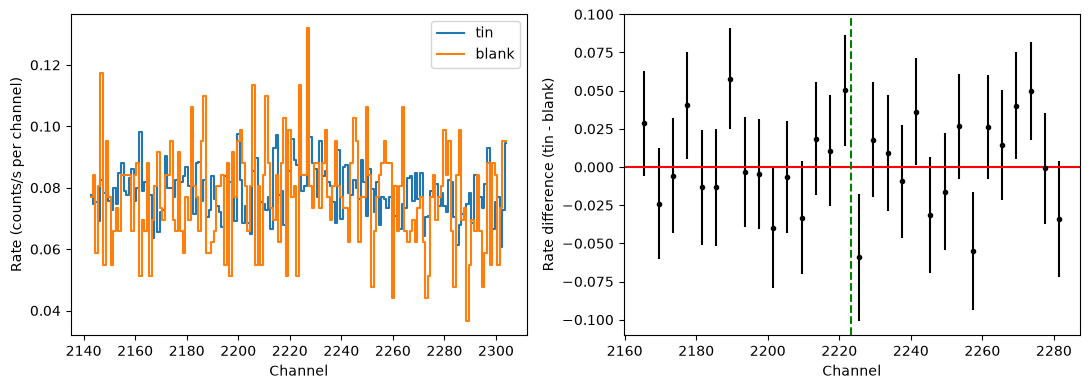

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, f, t in [(ax[0], ft, "with tin"), (ax[0], fb, "blank")]:
    pass
ax[0].step(ft['x'], ft['y']/L_t, where="mid", label="tin"); ax[0].step(fb['x'], fb['y']/L_b, where="mid", label="blank")
ax[0].set_xlabel("Channel"); ax[0].set_ylabel("Rate (counts/s per channel)"); ax[0].legend()
c, d, e = difference_spectrum(ch_t, n_t, L_t, n_b, L_b, rebin=4)
m = (c > mu - 60) & (c < mu + 60)
ax[1].errorbar(c[m], d[m], yerr=e[m], fmt=".", color="k"); ax[1].axhline(0, color="r"); ax[1].axvline(mu, color="g", ls="--")
ax[1].set_xlabel("Channel"); ax[1].set_ylabel("Rate difference (tin - blank)")
plt.tight_layout()